In [ ]:
from google.colab import drive

drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [ ]:
import os

print(os.path.exists('/content/gdrive/MyDrive'))
print(os.listdir('/content/gdrive/MyDrive')[:10])

True
['Colab Notebooks', '(134)A.SAHASRA FATHER ....vcf', 'APPLE', 'KOUSHIKEYA', 'INSTA', 'INTERVIEW', 'PUNCH.pdf', 'Untitled drawing (3).gdraw', 'Untitled drawing (2).gdraw', 'Untitled drawing (1).gdraw']


In [ ]:
import os

folder = "/content/drive/MyDrive/RoadCondition_DL_Results"

for root, dirs, files in os.walk(folder):
    print("\nFolder:", root)
    for file in files:
        print("  ", file)


Folder: /content/drive/MyDrive/RoadCondition_DL_Results

Folder: /content/drive/MyDrive/RoadCondition_DL_Results/ROC_Curves


In [ ]:
import os

ZIP_PATH = "/content/gdrive/MyDrive/road_dataset_zip.zip"

print("ZIP exists:", os.path.exists(ZIP_PATH))

if os.path.exists(ZIP_PATH):
    print(
        "File size (MB):",
        round(os.path.getsize(ZIP_PATH) / (1024 * 1024), 2)
    )

ZIP exists: True
File size (MB): 250.93


In [ ]:
import os
import zipfile

ZIP_PATH = "/content/gdrive/MyDrive/road_dataset_zip.zip"
EXTRACT_PATH = "/content/road_data"

# Verify ZIP
assert os.path.exists(ZIP_PATH), "Dataset ZIP not found!"

# Extract
with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset extracted successfully!")

# Locate class folders
class_names = ['smooth', 'crack', 'pothole']
DATASET_PATH = None

for root, dirs, files in os.walk(EXTRACT_PATH):
    if all(cls in dirs for cls in class_names):
        DATASET_PATH = root
        break

assert DATASET_PATH is not None, "Class folders not found!"

print("Dataset path:", DATASET_PATH)

# Count images
extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.gif')
total = 0

for cls in class_names:
    folder = os.path.join(DATASET_PATH, cls)
    count = sum(
        f.lower().endswith(extensions)
        for f in os.listdir(folder)
    )
    total += count
    print(f"{cls}: {count} images")

print("Total images:", total)

Dataset extracted successfully!
Dataset path: /content/road_data/road_dataset
smooth: 367 images
crack: 100 images
pothole: 100 images
Total images: 567


In [ ]:
class_names = ['smooth', 'crack', 'pothole']

DATASET_PATH = None

for root, dirs, files in os.walk(EXTRACT_PATH):
    if all(cls in dirs for cls in class_names):
        DATASET_PATH = root
        break

if DATASET_PATH is None:
    raise FileNotFoundError("Could not locate all three class folders.")

print("Dataset path:", DATASET_PATH)

Dataset path: /content/road_data/road_dataset


In [ ]:
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.gif')

total_images = 0

for class_name in class_names:
    folder = os.path.join(DATASET_PATH, class_name)

    count = sum(
        1 for f in os.listdir(folder)
        if f.lower().endswith(image_extensions)
    )

    total_images += count
    print(f"{class_name}: {count}")

print("Total images:", total_images)

smooth: 367
crack: 100
pothole: 100
Total images: 567


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from collections import Counter

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 16
SEED = 42
NUM_CLASSES = 3

class_names = ['smooth', 'crack', 'pothole']

class_to_index = {
    'smooth': 0,
    'crack': 1,
    'pothole': 2
}

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Classes:", class_to_index)

Image size: 224
Batch size: 16
Classes: {'smooth': 0, 'crack': 1, 'pothole': 2}


In [ ]:
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.gif')

file_paths = []
labels = []

for class_name in class_names:

    folder_path = os.path.join(DATASET_PATH, class_name)

    for filename in os.listdir(folder_path):

        if filename.lower().endswith(image_extensions):

            image_path = os.path.join(folder_path, filename)

            file_paths.append(image_path)
            labels.append(class_to_index[class_name])

file_paths = np.array(file_paths)
labels = np.array(labels)

print("Total images:", len(file_paths))
print("Total labels:", len(labels))
print("Image paths and labels created!")

Total images: 567
Total labels: 567
Image paths and labels created!


In [ ]:
# First separate the test set (15%)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    file_paths,
    labels,
    test_size=0.15,
    random_state=SEED,
    stratify=labels
)

# Then separate validation set (15% of total)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.17647,
    random_state=SEED,
    stratify=y_train_val
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))
print("Total:", len(X_train) + len(X_val) + len(X_test))

Training images: 396
Validation images: 85
Testing images: 86
Total: 567


In [ ]:
def show_distribution(name, labels):

    counts = Counter(labels)

    print(f"\n{name}")

    for class_name, index in class_to_index.items():
        print(f"{class_name}: {counts[index]}")

show_distribution("TRAINING", y_train)
show_distribution("VALIDATION", y_val)
show_distribution("TESTING", y_test)


TRAINING
smooth: 256
crack: 70
pothole: 70

VALIDATION
smooth: 55
crack: 15
pothole: 15

TESTING
smooth: 56
crack: 15
pothole: 15


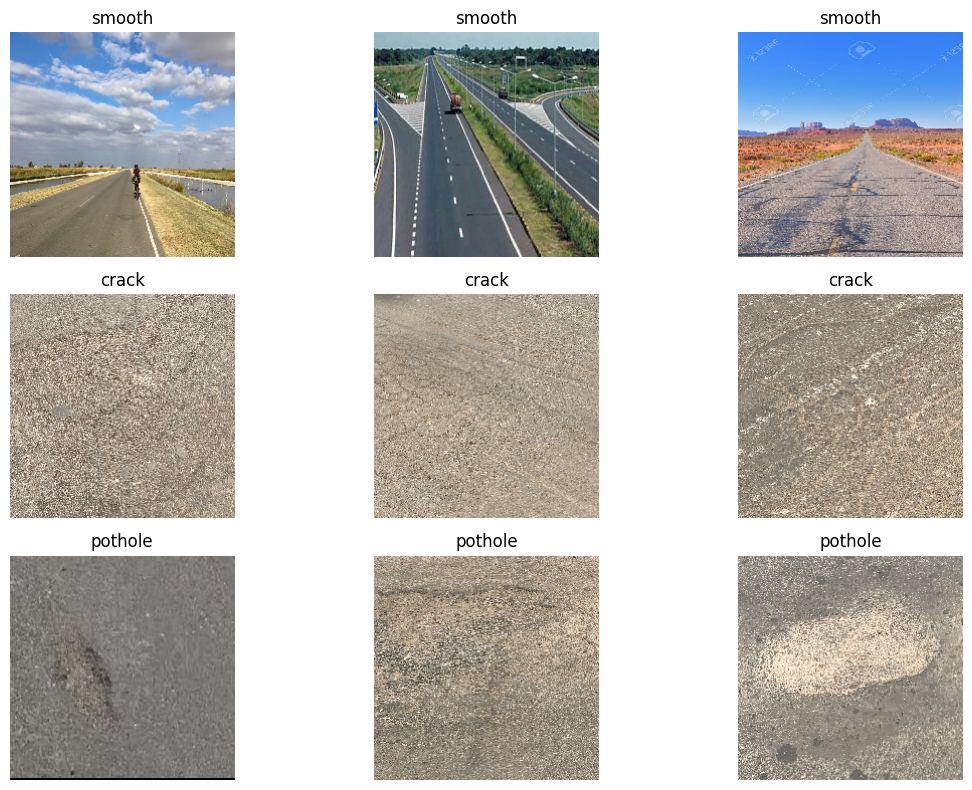

In [ ]:
plt.figure(figsize=(12, 8))

for i, class_name in enumerate(class_names):

    folder = os.path.join(DATASET_PATH, class_name)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith(image_extensions)
    ]

    for j in range(3):

        image_path = os.path.join(folder, images[j])

        img = tf.keras.utils.load_img(
            image_path,
            target_size=(IMG_SIZE, IMG_SIZE)
        )

        plt.subplot(3, 3, i * 3 + j + 1)
        plt.imshow(img)
        plt.title(class_name)
        plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:

AUTOTUNE = tf.data.AUTOTUNE

def load_image(image_path, label):

    # Read image from disk
    image = tf.io.read_file(image_path)

    # Decode JPG, JPEG, PNG and GIF
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Set image shape
    image.set_shape([None, None, 3])

    # Resize to 224 x 224
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    # Keep pixel values in range 0–255
    image = tf.cast(image, tf.float32)

    return image, label


print("Image loading function created!")


Image loading function created!


In [ ]:

def create_dataset(paths, labels, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=SEED
        )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(X_train, y_train, training=True)
val_ds = create_dataset(X_val, y_val)
test_ds = create_dataset(X_test, y_test)

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))


Training batches: 25
Validation batches: 6
Testing batches: 6


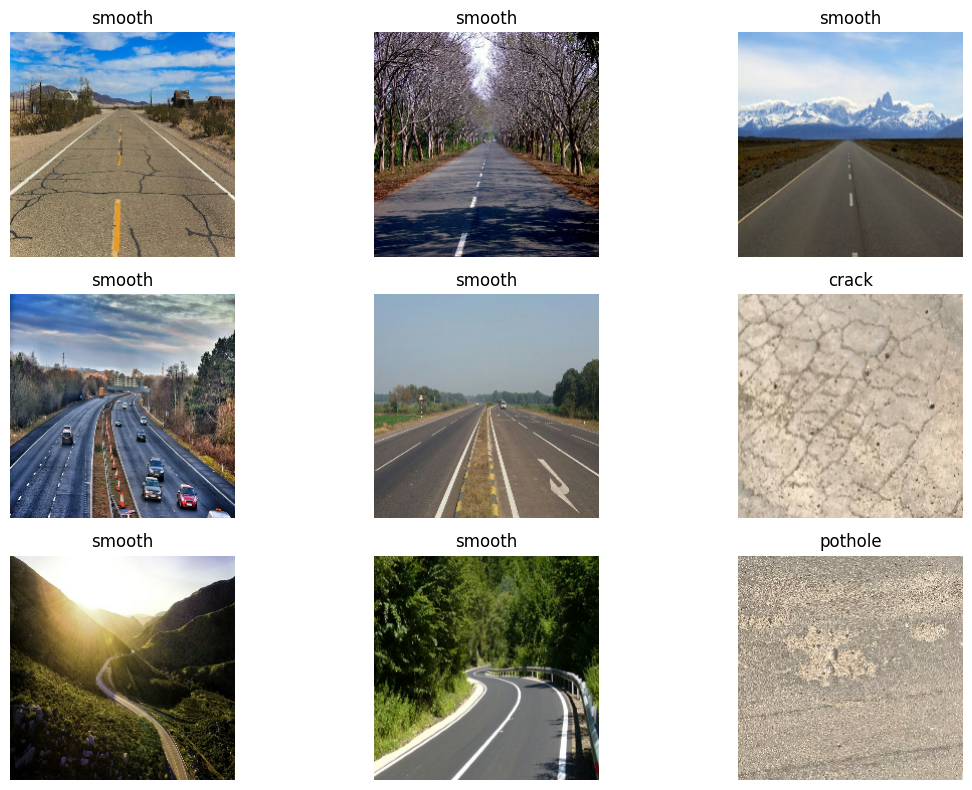

In [ ]:

plt.figure(figsize=(12, 8))

for images, labels_batch in train_ds.take(1):

    for i in range(9):

        plt.subplot(3, 3, i + 1)

        plt.imshow(
            images[i].numpy().astype("uint8")
        )

        plt.title(class_names[int(labels_batch[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.03),
    tf.keras.layers.RandomZoom(0.08),
    tf.keras.layers.RandomContrast(0.10)
], name="data_augmentation")

print("Updated augmentation pipeline created!")

Updated augmentation pipeline created!


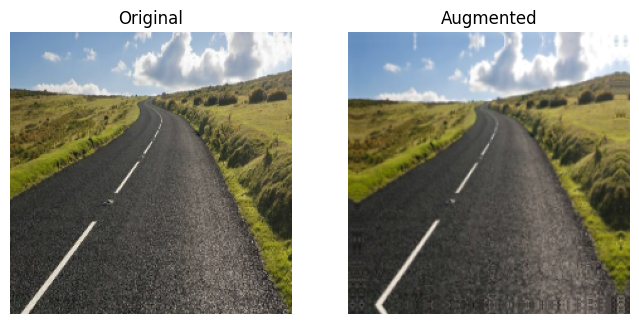

In [ ]:

for images, labels_batch in train_ds.take(1):

    sample_image = images[0:1]

    augmented_images = data_augmentation(
        sample_image,
        training=True
    )

    plt.figure(figsize=(8, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(sample_image[0].numpy().astype("uint8"))
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(
        tf.clip_by_value(
            augmented_images[0], 0, 255
        ).numpy().astype("uint8")
    )
    plt.title("Augmented")
    plt.axis("off")

    plt.show()


In [ ]:
from tensorflow.keras import layers, models

def build_custom_cnn():

    model = models.Sequential([

        layers.Input(shape=(224, 224, 3)),

        # Data augmentation
        data_augmentation,

        # Normalize pixels
        layers.Rescaling(1./255),

        # Block 1
        layers.Conv2D(32, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2, 2),

        # Block 2
        layers.Conv2D(64, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2, 2),

        # Block 3
        layers.Conv2D(128, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2, 2),

        # Block 4
        layers.Conv2D(256, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2, 2),

        # Classification
        layers.GlobalAveragePooling2D(),

        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),

        layers.Dense(NUM_CLASSES, activation='softmax')

    ])

    return model


cnn_model = build_custom_cnn()

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 423,619 (1.62 MB)

 Trainable params: 422,659 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
cnn_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

print("Custom CNN compiled successfully!")

Custom CNN compiled successfully!


In [ ]:
callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        'best_custom_cnn.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )

]

print("Training callbacks configured!")

Training callbacks configured!


In [ ]:
EPOCHS_CNN = 30

history_cnn = cnn_model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=EPOCHS_CNN,

    callbacks=callbacks

)

Epoch 1/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.6830 - loss: 0.7143
Epoch 1: val_loss improved from None to 1.13994, saving model to best_custom_cnn.keras

Epoch 1: finished saving model to best_custom_cnn.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 18s 180ms/step - accuracy: 0.7601 - loss: 0.5154 - val_accuracy: 0.3059 - val_loss: 1.1399 - learning_rate: 0.0010
Epoch 2/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.8053 - loss: 0.3376
Epoch 2: val_loss did not improve from 1.13994
25/25 ━━━━━━━━━━━━━━━━━━━━ 8s 104ms/step - accuracy: 0.8005 - loss: 0.3539 - val_accuracy: 0.1765 - val_loss: 1.3910 - learning_rate: 0.0010
Epoch 3/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.8499 - loss: 0.2830
Epoch 3: val_loss improved from 1.13994 to 1.10100, saving model to best_custom_cnn.keras

Epoch 3: finished saving model to best_custom_cnn.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 10s 139ms/step - accuracy: 0.8207 - loss: 0.3174 - val_accuracy: 0.4118 - val_loss: 1.1010 - lea

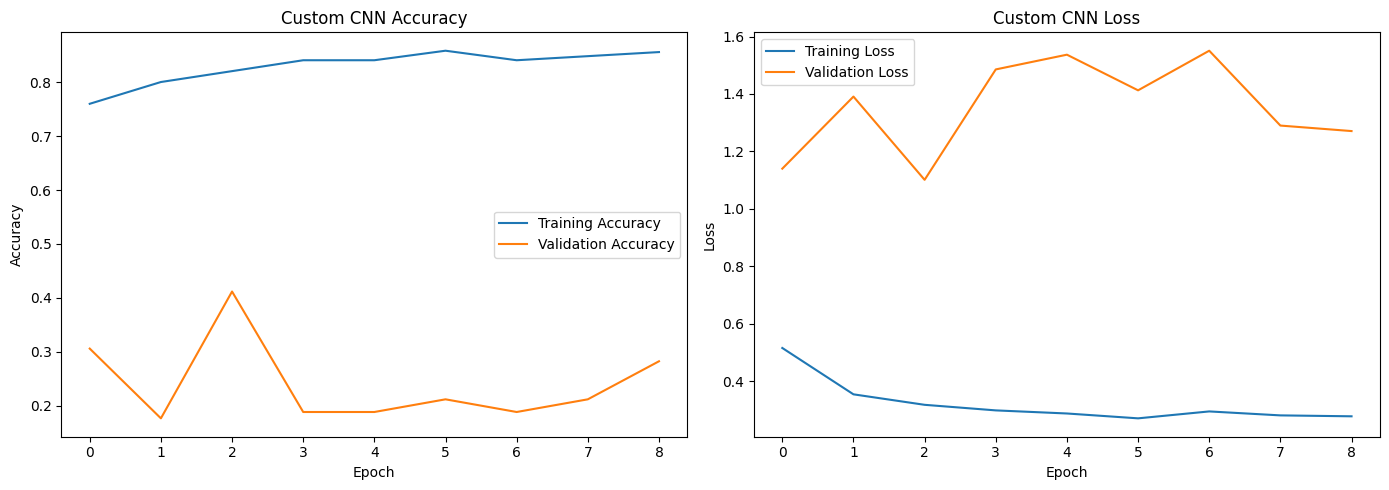

In [ ]:
plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(history_cnn.history['accuracy'], label='Training Accuracy')
plt.plot(history_cnn.history['val_accuracy'], label='Validation Accuracy')

plt.title('Custom CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)

plt.plot(history_cnn.history['loss'], label='Training Loss')
plt.plot(history_cnn.history['val_loss'], label='Validation Loss')

plt.title('Custom CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
best_epoch = np.argmin(history_cnn.history['val_loss']) + 1

best_val_loss = min(history_cnn.history['val_loss'])

best_val_accuracy = history_cnn.history['val_accuracy'][best_epoch - 1]

print("Best Epoch:", best_epoch)
print("Best Validation Loss:", round(best_val_loss, 4))
print("Validation Accuracy at Best Epoch:", round(best_val_accuracy * 100, 2), "%")

Best Epoch: 3
Best Validation Loss: 1.101
Validation Accuracy at Best Epoch: 41.18 %


In [ ]:
best_cnn = tf.keras.models.load_model(
    'best_custom_cnn.keras'
)

print("Best Custom CNN checkpoint loaded!")

Best Custom CNN checkpoint loaded!


In [ ]:
test_loss, test_accuracy = best_cnn.evaluate(test_ds)

print("\nCUSTOM CNN TEST RESULTS")
print("-" * 35)
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 176ms/step - accuracy: 0.4767 - loss: 0.9959

CUSTOM CNN TEST RESULTS
-----------------------------------
Test Loss: 0.9959
Test Accuracy: 47.67 %


6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step
CLASSIFICATION REPORT
              precision    recall  f1-score   support

      smooth     0.6538    0.6071    0.6296        56
       crack     0.0000    0.0000    0.0000        15
     pothole     0.2059    0.4667    0.2857        15

    accuracy                         0.4767        86
   macro avg     0.2866    0.3579    0.3051        86
weighted avg     0.4617    0.4767    0.4598        86



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


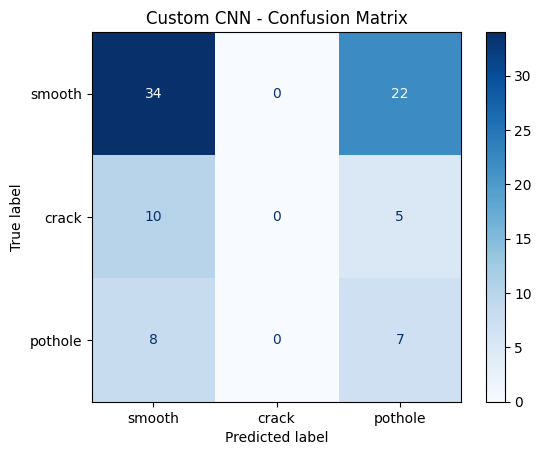

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Predicted probabilities
y_prob = best_cnn.predict(test_ds)

# Predicted classes
y_pred = np.argmax(y_prob, axis=1)

print("CLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap='Blues', values_format='d')
plt.title("Custom CNN - Confusion Matrix")
plt.show()

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class weights:", class_weights)

Class weights: {0: 0.515625, 1: 1.8857142857142857, 2: 1.8857142857142857}


In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras import layers, Model

print("ResNet50 imported successfully!")

ResNet50 imported successfully!


In [ ]:
def build_resnet50():

    # Load pretrained ResNet50
    base_model = ResNet50(
        weights='imagenet',
        include_top=False,
        input_shape=(224, 224, 3)
    )

    # Freeze pretrained layers
    base_model.trainable = False

    inputs = layers.Input(shape=(224, 224, 3))

    # Augmentation
    x = data_augmentation(inputs)

    # ResNet50-specific preprocessing
    x = preprocess_input(x)

    # Feature extraction
    x = base_model(x, training=False)

    # Classification head
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.BatchNormalization()(x)

    x = layers.Dense(
        256,
        activation='relu'
    )(x)

    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation='softmax'
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name="Road_Condition_ResNet50"
    )

    return model, base_model


resnet_model, resnet_base = build_resnet50()

resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "Road_Condition_ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer_3[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ data_augmentatio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 2048)      │      8,192 │ global_average_p… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 256)       │    524,544 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 3)         │        771 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 24,121,219 (92.02 MB)

 Trainable params: 529,411 (2.02 MB)

 Non-trainable params: 23,591,808 (90.00 MB)

In [ ]:
resnet_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

print("ResNet50 compiled successfully!")

ResNet50 compiled successfully!


In [ ]:
resnet_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        'best_resnet50.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

print("ResNet50 callbacks configured!")

ResNet50 callbacks configured!


In [ ]:
EPOCHS_RESNET = 25

history_resnet = resnet_model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=EPOCHS_RESNET,

    class_weight=class_weights,

    callbacks=resnet_callbacks
)

Epoch 1/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.5652 - loss: 1.2479
Epoch 1: val_loss improved from None to 0.28340, saving model to best_resnet50.keras

Epoch 1: finished saving model to best_resnet50.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 22s 372ms/step - accuracy: 0.6212 - loss: 0.9972 - val_accuracy: 0.8353 - val_loss: 0.2834 - learning_rate: 1.0000e-04
Epoch 2/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.7942 - loss: 0.5821
Epoch 2: val_loss improved from 0.28340 to 0.17358, saving model to best_resnet50.keras

Epoch 2: finished saving model to best_resnet50.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 16s 151ms/step - accuracy: 0.8207 - loss: 0.5482 - val_accuracy: 0.9647 - val_loss: 0.1736 - learning_rate: 1.0000e-04
Epoch 3/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.8297 - loss: 0.4499
Epoch 3: val_loss improved from 0.17358 to 0.13909, saving model to best_resnet50.keras

Epoch 3: finished saving model to best_resnet50.keras
25/25 ━━━━━━━━━━━━━━━━━━━━

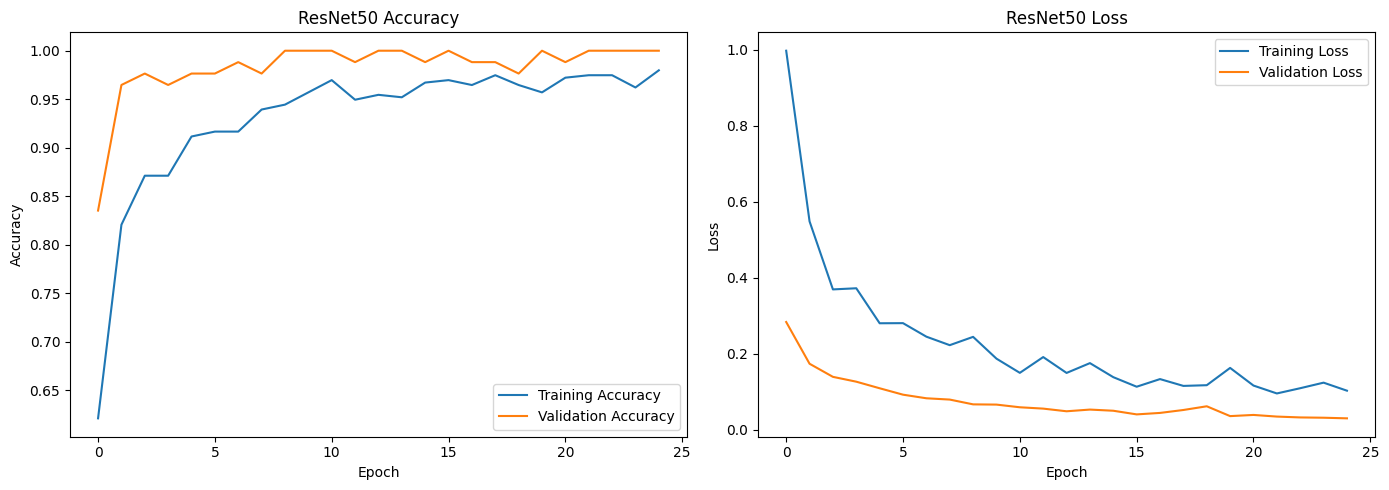

In [ ]:
plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    history_resnet.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_resnet.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('ResNet50 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    history_resnet.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_resnet.history['val_loss'],
    label='Validation Loss'
)

plt.title('ResNet50 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
best_resnet_epoch = (
    np.argmin(history_resnet.history['val_loss']) + 1
)

best_resnet_val_loss = min(
    history_resnet.history['val_loss']
)

best_resnet_val_accuracy = (
    history_resnet.history['val_accuracy'][
        best_resnet_epoch - 1
    ]
)

print("RESNET50 RESULTS")
print("-" * 35)

print("Best Epoch:", best_resnet_epoch)

print(
    "Best Validation Loss:",
    round(best_resnet_val_loss, 4)
)

print(
    "Validation Accuracy:",
    round(best_resnet_val_accuracy * 100, 2),
    "%"
)

RESNET50 RESULTS
-----------------------------------
Best Epoch: 25
Best Validation Loss: 0.0299
Validation Accuracy: 100.0 %


In [ ]:
best_resnet = tf.keras.models.load_model(
    'best_resnet50.keras'
)

resnet_base = best_resnet.get_layer('resnet50')

print("Best initial ResNet50 loaded!")

Best initial ResNet50 loaded!


In [ ]:
# Enable fine-tuning
resnet_base.trainable = True

# Freeze all layers initially
for layer in resnet_base.layers:
    layer.trainable = False

# Unfreeze only the last 30 layers
for layer in resnet_base.layers[-30:]:
    if not isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = True

print("Trainable layers:",
      sum(layer.trainable for layer in resnet_base.layers))

print("Total ResNet50 layers:", len(resnet_base.layers))

Trainable layers: 21
Total ResNet50 layers: 175


In [ ]:
best_resnet.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("ResNet50 recompiled for fine-tuning!")

ResNet50 recompiled for fine-tuning!


In [ ]:
fine_tune_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        'best_resnet50_finetuned.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_resnet_ft = best_resnet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    class_weight=class_weights,
    callbacks=fine_tune_callbacks
)

Epoch 1/12
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.9753 - loss: 0.0930
Epoch 1: val_loss improved from None to 0.01835, saving model to best_resnet50_finetuned.keras

Epoch 1: finished saving model to best_resnet50_finetuned.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 22s 352ms/step - accuracy: 0.9823 - loss: 0.0777 - val_accuracy: 1.0000 - val_loss: 0.0184 - learning_rate: 1.0000e-05
Epoch 2/12
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.9878 - loss: 0.0581
Epoch 2: val_loss did not improve from 0.01835
25/25 ━━━━━━━━━━━━━━━━━━━━ 7s 137ms/step - accuracy: 0.9823 - loss: 0.0767 - val_accuracy: 1.0000 - val_loss: 0.0225 - learning_rate: 1.0000e-05
Epoch 3/12
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.9808 - loss: 0.0837
Epoch 3: val_loss did not improve from 0.01835

Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
25/25 ━━━━━━━━━━━━━━━━━━━━ 9s 154ms/step - accuracy: 0.9823 - loss: 0.0693 - val_accuracy: 0.9882 - val_loss: 0.0362 - l

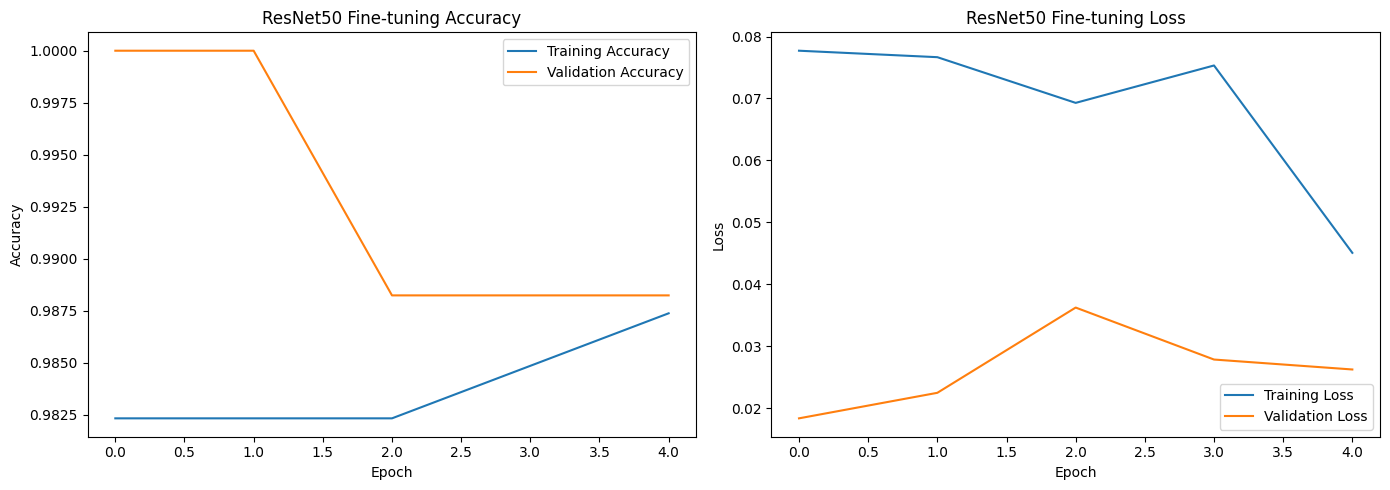

In [ ]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(
    history_resnet_ft.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_resnet_ft.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('ResNet50 Fine-tuning Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(
    history_resnet_ft.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_resnet_ft.history['val_loss'],
    label='Validation Loss'
)

plt.title('ResNet50 Fine-tuning Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
initial_best_loss = min(
    history_resnet.history['val_loss']
)

fine_tuned_best_loss = min(
    history_resnet_ft.history['val_loss']
)

print("Initial ResNet50 validation loss:",
      round(initial_best_loss, 4))

print("Fine-tuned ResNet50 validation loss:",
      round(fine_tuned_best_loss, 4))

if fine_tuned_best_loss < initial_best_loss:

    print("Fine-tuned ResNet50 selected!")

    final_resnet = tf.keras.models.load_model(
        'best_resnet50_finetuned.keras'
    )

    final_resnet_version = "Fine-tuned"

else:

    print("Initial ResNet50 selected!")

    final_resnet = tf.keras.models.load_model(
        'best_resnet50.keras'
    )

    final_resnet_version = "Initial"

print("Selected version:", final_resnet_version)

Initial ResNet50 validation loss: 0.0299
Fine-tuned ResNet50 validation loss: 0.0184
Fine-tuned ResNet50 selected!
Selected version: Fine-tuned


In [ ]:
resnet_test_loss, resnet_test_accuracy = final_resnet.evaluate(
    test_ds
)

print("\nFINAL RESNET50 TEST RESULTS")
print("-" * 40)

print("Selected version:", final_resnet_version)
print("Test Loss:", round(resnet_test_loss, 4))
print("Test Accuracy:", round(resnet_test_accuracy * 100, 2), "%")

6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 391ms/step - accuracy: 0.9302 - loss: 0.2159

FINAL RESNET50 TEST RESULTS
----------------------------------------
Selected version: Fine-tuned
Test Loss: 0.2159
Test Accuracy: 93.02 %


6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 389ms/step
              precision    recall  f1-score   support

      smooth     1.0000    1.0000    1.0000        56
       crack     1.0000    0.6000    0.7500        15
     pothole     0.7143    1.0000    0.8333        15

    accuracy                         0.9302        86
   macro avg     0.9048    0.8667    0.8611        86
weighted avg     0.9502    0.9302    0.9273        86



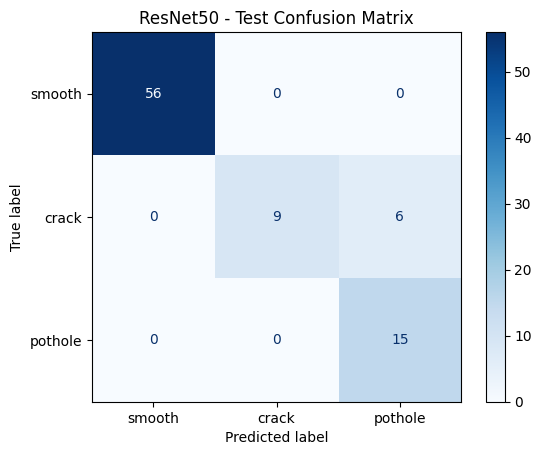

In [ ]:
y_true_resnet = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob_resnet = final_resnet.predict(test_ds)

y_pred_resnet = np.argmax(y_prob_resnet, axis=1)

print(classification_report(
    y_true_resnet,
    y_pred_resnet,
    target_names=class_names,
    digits=4
))

cm_resnet = confusion_matrix(
    y_true_resnet,
    y_pred_resnet,
    labels=[0, 1, 2]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_resnet,
    display_labels=class_names
).plot(cmap='Blues', values_format='d')

plt.title("ResNet50 - Test Confusion Matrix")
plt.show()

In [ ]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, Model

print("EfficientNetB0 imported successfully!")

EfficientNetB0 imported successfully!


In [ ]:
def build_efficientnet():

    base_model = EfficientNetB0(
        weights='imagenet',
        include_top=False,
        input_shape=(224, 224, 3)
    )

    # Freeze pretrained layers initially
    base_model.trainable = False

    inputs = layers.Input(shape=(224, 224, 3))

    # Data augmentation
    x = data_augmentation(inputs)

    # EfficientNetB0 includes its own input rescaling
    x = base_model(x, training=False)

    # Classification head
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.BatchNormalization()(x)

    x = layers.Dense(
        256,
        activation='relu'
    )(x)

    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation='softmax'
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name="Road_Condition_EfficientNetB0"
    )

    return model, base_model


efficient_model, efficient_base = build_efficientnet()

efficient_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "Road_Condition_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,383,398 (16.72 MB)

 Trainable params: 331,267 (1.26 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [ ]:
efficient_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

print("EfficientNetB0 compiled successfully!")

EfficientNetB0 compiled successfully!


In [ ]:
efficient_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        'best_efficientnetb0.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

print("EfficientNetB0 callbacks configured!")

EfficientNetB0 callbacks configured!


In [ ]:
EPOCHS_EFFICIENT = 25

history_efficient = efficient_model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=EPOCHS_EFFICIENT,

    class_weight=class_weights,

    callbacks=efficient_callbacks
)

Epoch 1/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.6463 - loss: 1.0252
Epoch 1: val_loss improved from None to 0.45840, saving model to best_efficientnetb0.keras

Epoch 1: finished saving model to best_efficientnetb0.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 24s 395ms/step - accuracy: 0.7348 - loss: 0.8213 - val_accuracy: 0.8706 - val_loss: 0.4584 - learning_rate: 1.0000e-04
Epoch 2/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.8623 - loss: 0.4756
Epoch 2: val_loss improved from 0.45840 to 0.34803, saving model to best_efficientnetb0.keras

Epoch 2: finished saving model to best_efficientnetb0.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 15s 116ms/step - accuracy: 0.8535 - loss: 0.4490 - val_accuracy: 0.8706 - val_loss: 0.3480 - learning_rate: 1.0000e-04
Epoch 3/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.8728 - loss: 0.4278
Epoch 3: val_loss improved from 0.34803 to 0.28095, saving model to best_efficientnetb0.keras

Epoch 3: finished saving model to best_efficientnet

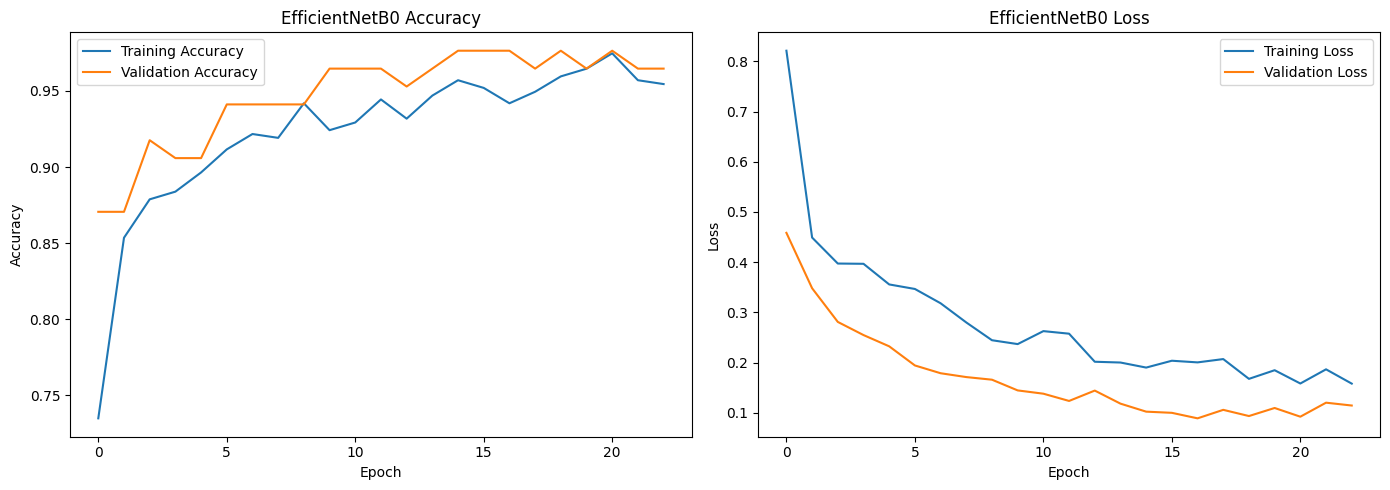

In [ ]:
plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    history_efficient.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_efficient.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('EfficientNetB0 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    history_efficient.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_efficient.history['val_loss'],
    label='Validation Loss'
)

plt.title('EfficientNetB0 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
best_efficient_epoch = (
    np.argmin(history_efficient.history['val_loss']) + 1
)

best_efficient_val_loss = min(
    history_efficient.history['val_loss']
)

best_efficient_val_accuracy = (
    history_efficient.history['val_accuracy'][
        best_efficient_epoch - 1
    ]
)

print("EFFICIENTNETB0 RESULTS")
print("-" * 40)

print("Best Epoch:", best_efficient_epoch)

print(
    "Best Validation Loss:",
    round(best_efficient_val_loss, 4)
)

print(
    "Validation Accuracy:",
    round(best_efficient_val_accuracy * 100, 2),
    "%"
)

EFFICIENTNETB0 RESULTS
----------------------------------------
Best Epoch: 17
Best Validation Loss: 0.0889
Validation Accuracy: 97.65 %


In [ ]:
efficient_base.trainable = True

# Freeze all layers first
for layer in efficient_base.layers:
    layer.trainable = False

# Unfreeze final 30 layers, except BatchNormalization
for layer in efficient_base.layers[-30:]:

    if not isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = True

print(
    "Trainable layers:",
    sum(layer.trainable for layer in efficient_base.layers)
)

Trainable layers: 23


In [ ]:
efficient_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

In [ ]:
efficient_ft_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        'best_efficientnetb0_finetuned.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_efficient_ft = efficient_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    class_weight=class_weights,
    callbacks=efficient_ft_callbacks
)

Epoch 1/12
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.9542 - loss: 0.1761
Epoch 1: val_loss improved from None to 0.08710, saving model to best_efficientnetb0_finetuned.keras

Epoch 1: finished saving model to best_efficientnetb0_finetuned.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 21s 250ms/step - accuracy: 0.9495 - loss: 0.1936 - val_accuracy: 0.9765 - val_loss: 0.0871 - learning_rate: 1.0000e-05
Epoch 2/12
24/25 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.9711 - loss: 0.1669
Epoch 2: val_loss did not improve from 0.08710
25/25 ━━━━━━━━━━━━━━━━━━━━ 7s 104ms/step - accuracy: 0.9646 - loss: 0.1632 - val_accuracy: 0.9765 - val_loss: 0.0993 - learning_rate: 1.0000e-05
Epoch 3/12
24/25 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.9513 - loss: 0.2059
Epoch 3: val_loss did not improve from 0.08710

Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 104ms/step - accuracy: 0.9419 - loss: 0.2220 - val_accuracy: 0.9765 - val_loss: 0

In [ ]:
initial_efficient_loss = min(
    history_efficient.history['val_loss']
)

fine_tuned_efficient_loss = min(
    history_efficient_ft.history['val_loss']
)

print("Initial validation loss:", round(initial_efficient_loss, 4))
print("Fine-tuned validation loss:", round(fine_tuned_efficient_loss, 4))

if fine_tuned_efficient_loss < initial_efficient_loss:

    final_efficient = tf.keras.models.load_model(
        'best_efficientnetb0_finetuned.keras'
    )

    efficient_version = "Fine-tuned"

else:

    final_efficient = tf.keras.models.load_model(
        'best_efficientnetb0.keras'
    )

    efficient_version = "Initial"

print("Selected version:", efficient_version)

Initial validation loss: 0.0889
Fine-tuned validation loss: 0.0871
Selected version: Fine-tuned


In [ ]:
efficient_test_loss, efficient_test_accuracy = (
    final_efficient.evaluate(test_ds)
)

print("\nFINAL EFFICIENTNETB0 TEST RESULTS")
print("-" * 40)

print("Selected version:", efficient_version)
print("Test Loss:", round(efficient_test_loss, 4))
print(
    "Test Accuracy:",
    round(efficient_test_accuracy * 100, 2),
    "%"
)

6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 344ms/step - accuracy: 0.9419 - loss: 0.1493

FINAL EFFICIENTNETB0 TEST RESULTS
----------------------------------------
Selected version: Fine-tuned
Test Loss: 0.1493
Test Accuracy: 94.19 %


6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 570ms/step
              precision    recall  f1-score   support

      smooth     1.0000    1.0000    1.0000        56
       crack     1.0000    0.6667    0.8000        15
     pothole     0.7500    1.0000    0.8571        15

    accuracy                         0.9419        86
   macro avg     0.9167    0.8889    0.8857        86
weighted avg     0.9564    0.9419    0.9402        86



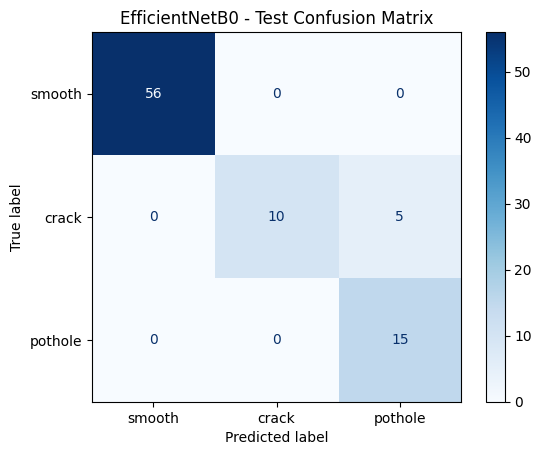

In [ ]:
y_true_efficient = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob_efficient = final_efficient.predict(test_ds)

y_pred_efficient = np.argmax(
    y_prob_efficient,
    axis=1
)

print(classification_report(
    y_true_efficient,
    y_pred_efficient,
    target_names=class_names,
    digits=4
))

cm_efficient = confusion_matrix(
    y_true_efficient,
    y_pred_efficient,
    labels=[0, 1, 2]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_efficient,
    display_labels=class_names
).plot(cmap='Blues', values_format='d')

plt.title("EfficientNetB0 - Test Confusion Matrix")
plt.show()

In [ ]:
import os
import shutil

OUTPUT_DIR = "/content/drive/MyDrive/RoadCondition_DL_Results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save selected models
best_cnn.save(
    os.path.join(OUTPUT_DIR, "Custom_CNN.keras")
)

final_resnet.save(
    os.path.join(OUTPUT_DIR, "ResNet50.keras")
)

final_efficient.save(
    os.path.join(OUTPUT_DIR, "EfficientNetB0.keras")
)

print("All three selected models saved!")
print("Location:", OUTPUT_DIR)

All three selected models saved!
Location: /content/drive/MyDrive/RoadCondition_DL_Results


,Model,Best Epoch,Validation Accuracy (%),Test Accuracy (%),Test Loss,Weighted F1 (%)
0,Custom CNN,29,85.88,84.88,0.2453,83.38
1,ResNet50,6,98.82,97.67,0.0474,97.66
2,EfficientNetB0,16,96.47,95.35,0.1053,95.26


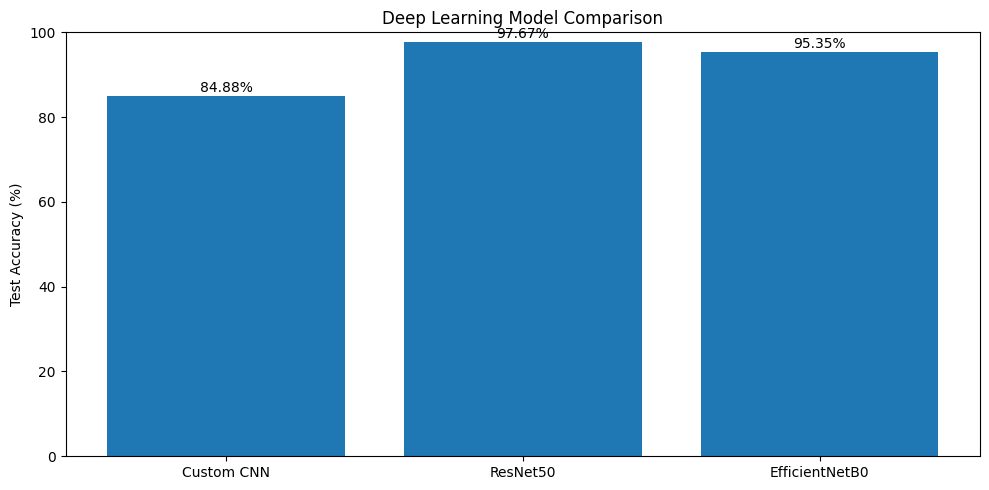

In [ ]:
results = pd.DataFrame({

    "Model": [
        "Custom CNN",
        "ResNet50",
        "EfficientNetB0"
    ],

    "Best Epoch": [
        29,
        6,
        16
    ],

    "Validation Accuracy (%)": [
        85.88,
        98.82,
        96.47
    ],

    "Test Accuracy (%)": [
        84.88,
        97.67,
        95.35
    ],

    "Test Loss": [
        0.2453,
        0.0474,
        0.1053
    ],

    "Weighted F1 (%)": [
        83.38,
        97.66,
        95.26
    ]
})

display(results)

results.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison.csv"),
    index=False
)

plt.figure(figsize=(10, 5))

plt.bar(
    results["Model"],
    results["Test Accuracy (%)"]
)

plt.ylabel("Test Accuracy (%)")
plt.title("Deep Learning Model Comparison")
plt.ylim(0, 100)

for i, value in enumerate(results["Test Accuracy (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "model_comparison.png"),
    dpi=300
)

plt.show()

Test samples: 86
Classes: ['Smooth', 'Crack', 'Pothole']

Generating ROC for: Custom CNN


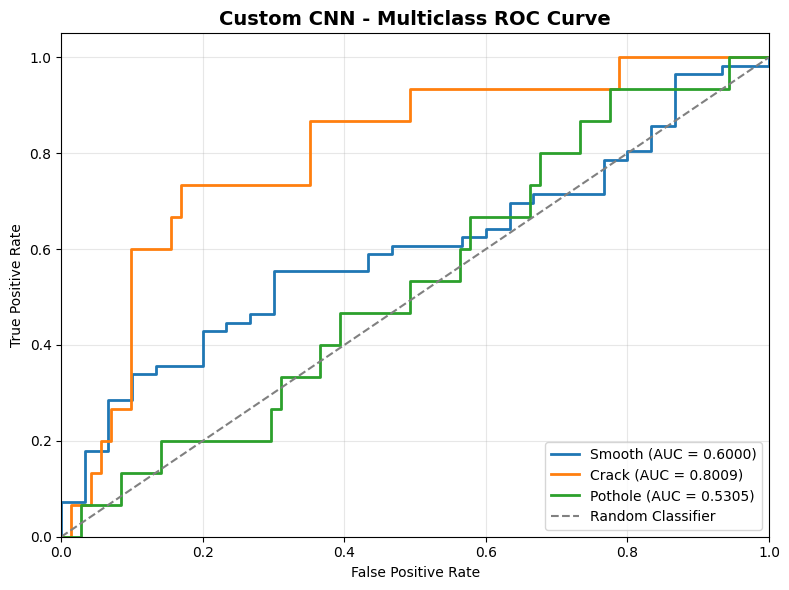


 Custom CNN AUC RESULTS
----------------------------------------
Smooth: 0.6000
Crack: 0.8009
Pothole: 0.5305
Micro Average: 0.6892
Macro Average: 0.6438

Generating ROC for: ResNet50


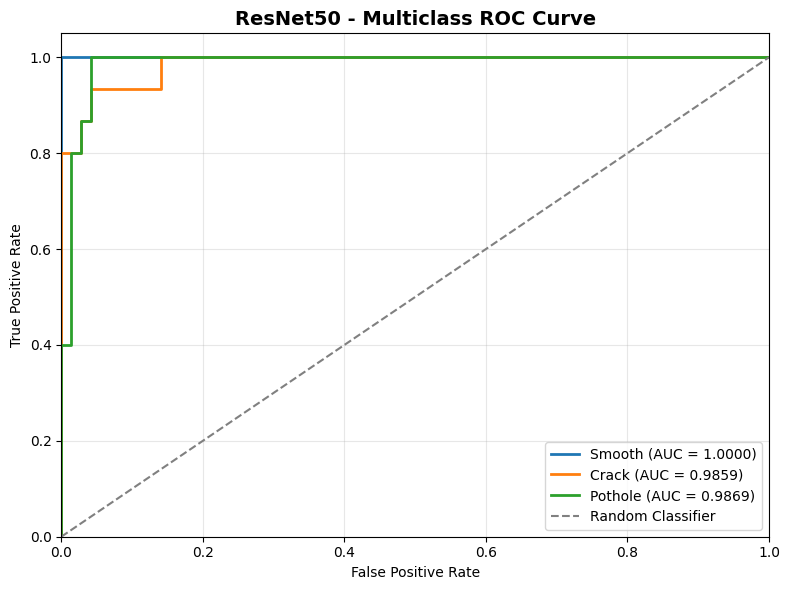


 ResNet50 AUC RESULTS
----------------------------------------
Smooth: 1.0000
Crack: 0.9859
Pothole: 0.9869
Micro Average: 0.9936
Macro Average: 0.9909

Generating ROC for: EfficientNetB0


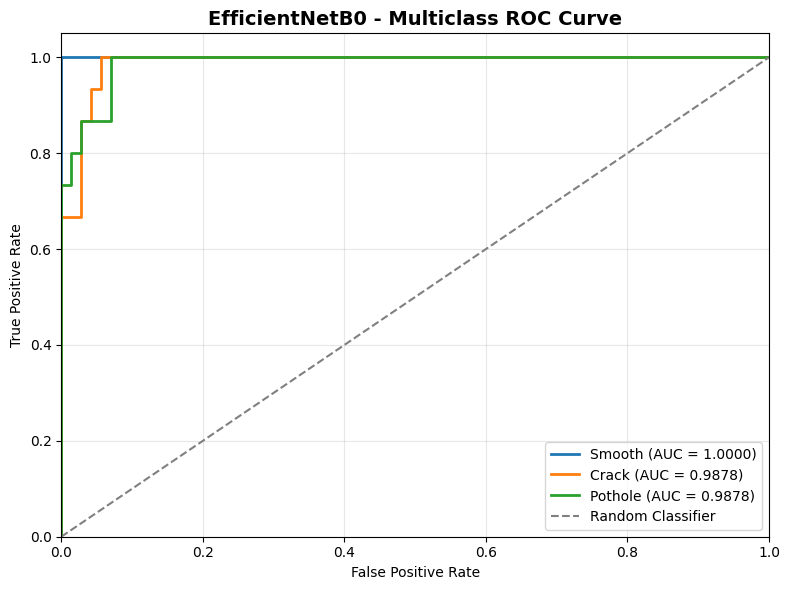


 EfficientNetB0 AUC RESULTS
----------------------------------------
Smooth: 1.0000
Crack: 0.9878
Pothole: 0.9878
Micro Average: 0.9932
Macro Average: 0.9919

FINAL AUC COMPARISON


,Smooth,Crack,Pothole,Micro Average,Macro Average
Custom CNN,60.0,80.09,53.05,68.92,64.38
ResNet50,100.0,98.59,98.69,99.36,99.09
EfficientNetB0,100.0,98.78,98.78,99.32,99.19



All ROC curves and AUC results saved!
Location: /content/drive/MyDrive/RoadCondition_DL_Results/ROC_Curves


In [ ]:

# ============================================
# ROC CURVES AND AUC FOR ALL THREE DL MODELS
# ============================================

import os
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    roc_curve,
    auc,
    roc_auc_score
)

# --------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------

CLASS_NAMES = ["Smooth", "Crack", "Pothole"]
CLASS_LABELS = [0, 1, 2]

OUTPUT_DIR = "/content/drive/MyDrive/RoadCondition_DL_Results/ROC_Curves"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# --------------------------------------------
# 2. GET ACTUAL TEST LABELS
# --------------------------------------------

y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

# Convert labels into one-vs-rest binary format
y_true_bin = label_binarize(
    y_true,
    classes=CLASS_LABELS
)

print("Test samples:", len(y_true))
print("Classes:", CLASS_NAMES)

# --------------------------------------------
# 3. SELECT TRAINED MODELS
# --------------------------------------------

models = {
    "Custom CNN": best_cnn,
    "ResNet50": final_resnet,
    "EfficientNetB0": final_efficient
}

# --------------------------------------------
# 4. GENERATE ROC CURVES
# --------------------------------------------

all_auc_results = {}

for model_name, model in models.items():

    print("\nGenerating ROC for:", model_name)

    # Get predicted probabilities
    y_score = model.predict(
        test_ds,
        verbose=0
    )

    # Store AUC results
    auc_results = {}

    plt.figure(figsize=(8, 6))

    # Plot ROC for each class
    for i, class_name in enumerate(CLASS_NAMES):

        fpr, tpr, thresholds = roc_curve(
            y_true_bin[:, i],
            y_score[:, i]
        )

        class_auc = auc(fpr, tpr)

        auc_results[class_name] = class_auc

        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{class_name} (AUC = {class_auc:.4f})"
        )

    # Micro-average AUC
    micro_auc = roc_auc_score(
        y_true_bin,
        y_score,
        average="micro"
    )

    # Macro-average AUC
    macro_auc = roc_auc_score(
        y_true_bin,
        y_score,
        average="macro"
    )

    auc_results["Micro Average"] = micro_auc
    auc_results["Macro Average"] = macro_auc

    # Random classifier reference
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray",
        label="Random Classifier"
    )

    # Chart formatting
    plt.title(
        f"{model_name} - Multiclass ROC Curve",
        fontsize=14,
        fontweight="bold"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")

    plt.xlim([0, 1])
    plt.ylim([0, 1.05])

    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)

    plt.tight_layout()

    # Save graph
    filename = (
        model_name.lower().replace(" ", "_")
        + "_roc_curve.png"
    )

    save_path = os.path.join(
        OUTPUT_DIR,
        filename
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    all_auc_results[model_name] = auc_results

    print("\n", model_name, "AUC RESULTS")
    print("-" * 40)

    for name, value in auc_results.items():
        print(f"{name}: {value:.4f}")

# --------------------------------------------
# 5. COMPARATIVE AUC TABLE
# --------------------------------------------

import pandas as pd

auc_df = pd.DataFrame(
    all_auc_results
).T

print("\nFINAL AUC COMPARISON")
print("=" * 60)

display(
    (auc_df * 100).round(2)
)

# Save results as CSV
auc_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "AUC_Comparison.csv"
    )
)

print("\nAll ROC curves and AUC results saved!")
print("Location:", OUTPUT_DIR)


In [ ]:

import numpy as np

# Actual labels from the held-out test dataset
y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

# Predictions from each selected model
cnn_probs = best_cnn.predict(test_ds, verbose=0)
resnet_probs = final_resnet.predict(test_ds, verbose=0)
efficient_probs = final_efficient.predict(test_ds, verbose=0)

# Save all required data into one file
np.savez(
    "/content/road_roc_predictions.npz",
    y_true=y_true,
    cnn_probs=cnn_probs,
    resnet_probs=resnet_probs,
    efficient_probs=efficient_probs
)

print("ROC prediction data exported successfully!")


ROC prediction data exported successfully!
